In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
def loss(a:np.ndarray,b:np.ndarray,func:callable = None) -> np.float64:
    assert len(a) == len(b)
    l = 0
    size = len(a)
    for x,y in zip(a,b):
        t = func(x)
        l += (t-y)**2
    l = l/size
    return l

def loss_a(a:np.ndarray,b:np.ndarray, slope, bias) -> np.float64:
    assert len(a) == len(b)
    func = lambda x : slope * x + bias
    l = 0
    size = len(a)
    scores = [func(x) for x in a]
    for x,y in zip(a,b):
        t = func(x)
        l += (t-y)**2
    l = l/size

    # L2 regularization
    alpha = 1e-4
    reg_loss = alpha * (slope**2 + bias**2)
    total_loss = l + reg_loss

    # also get accuracy
    accuracy = [(yi > 0) == (scorei > 0) for yi, scorei in zip(b, scores)]
    return total_loss, sum(accuracy) / len(accuracy)



949.1608118658212


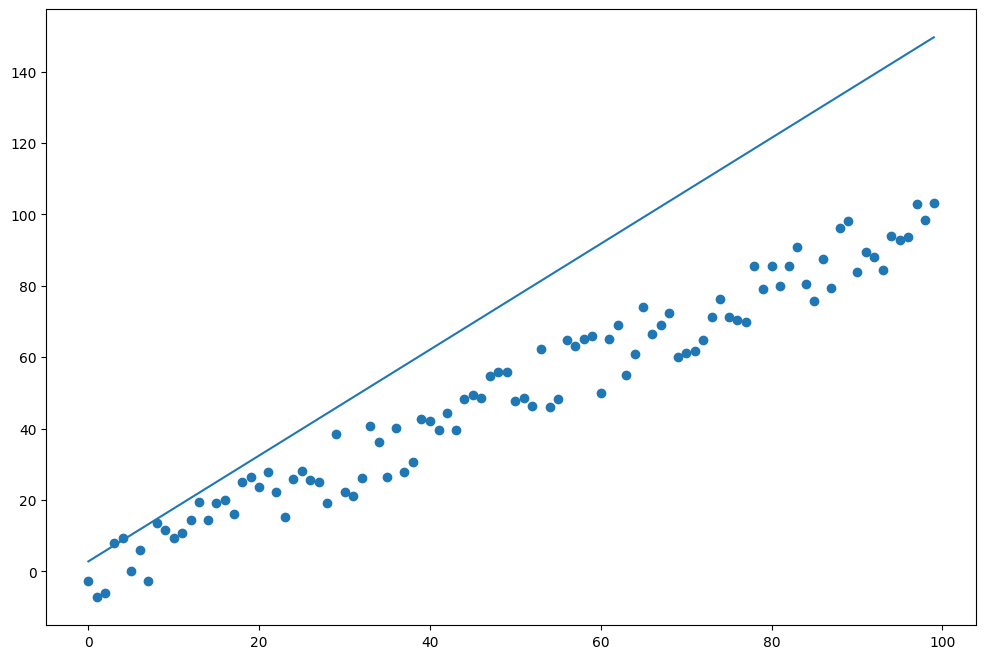

In [3]:
base = range(100)
a = np.array([x for x in base])
b = np.array([x + np.random.uniform(-10,10) for x in base])

slope = np.random.uniform(0,2)
bias = np.random.uniform(1,3)
f = lambda x: slope * x + bias
l_score = loss(a,b,f)
print(l_score)
plt.figure(figsize=(12,8))
plt.scatter(a,b)
plt.plot(a,f(a))
plt.show()

In [4]:
slopes = np.arange(0,3,0.25)
losses = []
for x in slopes:
    f = lambda y : x * y
    losses.append(loss(a,b,f))

dic = dict(zip(slopes, losses))
df = pd.DataFrame.from_dict(dic, orient="index")
df

,0
0.00,3305.474616
0.25,1872.066303
0.50,849.095490
0.75,236.562177
1.00,34.466365
1.25,242.808052
1.50,861.587239
1.75,1890.803926
2.00,3330.458113
2.25,5180.549801


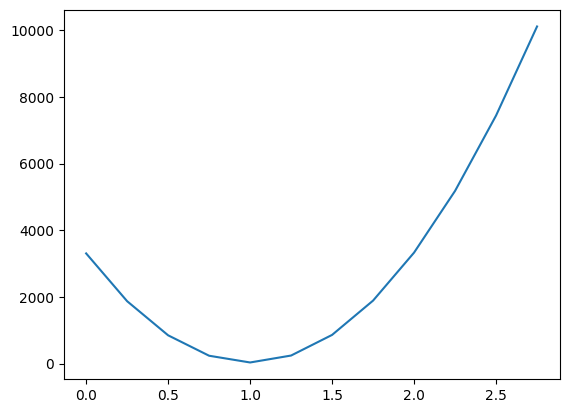

In [5]:
plt.plot(slopes,losses)

In [6]:
db = []
for i in range(len(a)):
    db.append((-2/len(a))*(f(a[i]) - b[i]))
db = np.array(db)
db

array([-0.05625627, -0.20032383, -0.23084902, -0.00875957, -0.03104153,
       -0.27187313, -0.20795916, -0.44149966, -0.16705199, -0.26119243,
       -0.3620423 , -0.3889625 , -0.37356821, -0.32731515, -0.48052826,
       -0.44039527, -0.47756001, -0.6152313 , -0.48662135, -0.51607178,
       -0.62667765, -0.59860793, -0.76393598, -0.96131248, -0.79995841,
       -0.81000914, -0.91531643, -0.98462015, -1.1569535 , -0.82320399,
       -1.20738542, -1.28085494, -1.23539722, -0.99853791, -1.14342079,
       -1.39386965, -1.17773959, -1.47974238, -1.47817049, -1.29176605,
       -1.35727205, -1.46397134, -1.4236606 , -1.57045964, -1.45595548,
       -1.48521349, -1.56082879, -1.49136032, -1.5250457 , -1.57786918,
       -1.79607086, -1.83606652, -1.93461778, -1.66969944, -2.05063384,
       -2.0586333 , -1.7855855 , -1.87054351, -1.88862713, -1.92659916,
       -2.29770947, -2.05109859, -2.03117686, -2.36715848, -2.30325499,
       -2.09603185, -2.29807523, -2.30612423, -2.29131658, -2.59

In [7]:
dm = []
for i in range(len(a)):
    dm.append((-2/len(a))*(f(a[i]) - b[i]) * a[i])
dm = np.array(dm)

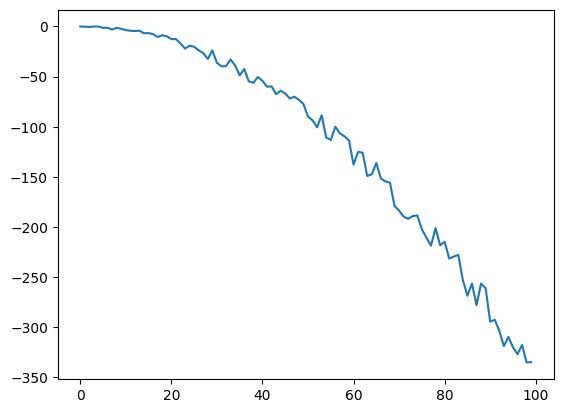

In [8]:
plt.plot(a,dm)

In [9]:
# llr = -0.0001
# epoch = 1000
# m = 2.75
# bias = 0
# f = lambda x : (m * x) + bias

# print(f"{'Iteration':^10} | {'Loss':^20} | {'Slope':^20} | {'Bias':^20}")

# for k in range(epoch):
#     # forward pass
#     l = loss(a,b,f)

#     # backward pass
#     db = []
#     for i in range(len(a)):
#         db.append((-2/len(a))*(f(a[i]) - b[i]))
#     lb = sum(db)

#     dm = []
#     for i in range(len(a)):
#         dm.append((-2/len(a))*(f(a[i]) - b[i]) * a[i])
#     lm = sum(dm)

#     # update
#     m = m - (llr * lm )
#     bias = bias - (llr * lb)

#     f = lambda x : (m * x) + bias

#     print(f"{k:<10} | {l:<20} | {m:<20} | {bias:<20}")

In [ ]:
# Stochastic Gradient Descent
llr = -0.0001
epoch = 10
m = 2.75
bias = 0
f = lambda x : (m * x) + bias
# LOSS_SGD = []
TLOSS = []
# print(f"{'Iteration':^10} | {'Loss':^20} | {'Accuracy':^20} | {'Slope':^20} | {'Bias':^20}")

for k in range(epoch):

    TLOSS.append(loss_a(a,b,m,bias))

    for x,y in zip(a,b):
        # forward pass
        l = y - (m*x+bias) 

        # backward pass
        grad_m = 0
        grad_b = 0

        mlen = -2/len(a)
        error = f(x) - y
        grad_b += mlen * error
        grad_m += mlen * error * x 

        # update
        m = m - (llr * grad_m )
        bias = bias - (llr * grad_b)


In [25]:
llr = -0.0001
epoch = 100
m = 2.75
bias = 0
f = lambda x : (m * x) + bias
LOSS_BGD = []
# print(f"{'Iteration':^10} | {'Loss':^20} | {'Accuracy':^20} | {'Slope':^20} | {'Bias':^20}")

for k in range(epoch):
    # forward pass
    l,accuracy = loss_a(a,b,m,bias)
    LOSS_BGD.append(l)
    
    # backward pass
    grad_m = 0
    grad_b = 0

    mlen = -2/len(a)
    for idx in range(len(a)):
        error = f(a[idx]) - b[idx]
        grad_b += mlen * error
        grad_m += mlen * error * a[i] 


    # update
    m = m - (llr * grad_m )
    bias = bias - (llr * grad_b)

    # print(f"{k:<10} | {l:<20} | {str(accuracy*100)+'%':^20} | {m:<20} | {bias:<20}")

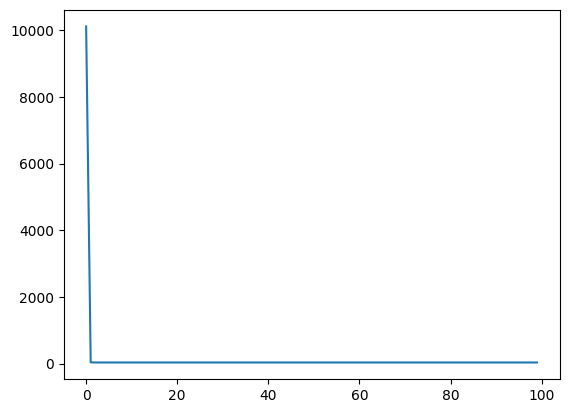

In [26]:
plt.plot(LOSS_BGD)

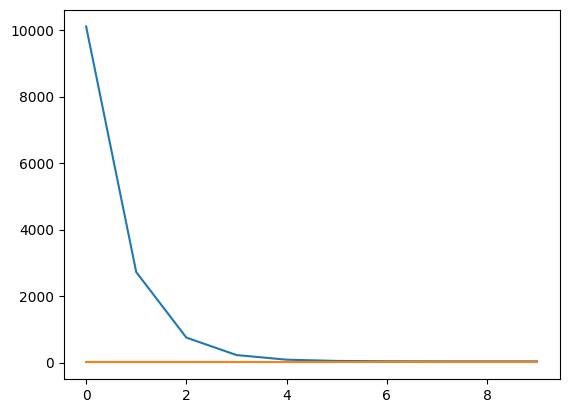

In [33]:
plt.plot(TLOSS)

In [34]:
TLOSS[-1]

(np.float64(34.51272976491054), np.float64(0.97))

In [35]:
LOSS_BGD[-1]

np.float64(34.47547913318717)